# picomake - activations_gradients

In [27]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
%matplotlib inline

In [28]:
words = open("names.txt", "r").read().split()
words[:3]

# build vocabulary

stoi = {}
stoi['.'] = 0
vocab = sorted(list(set(letters for word in words for letters in word)))
for i, ch in enumerate(vocab, start = 1):
    stoi[ch] = i
itos = {i:s for s,i in stoi.items()}
stoi

{'.': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

In [29]:
# build out dataset
def build_dataset(words):
    context_size = 3
    X = []
    Y = []

    for w in words:
        context = [0]*context_size

        for i in w+'.':
            ix = stoi[i]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context [1:] + [ix]


    X = torch.tensor(X) # X stores the context of one training example in chunk of context size (stoi)
    Y = torch.tensor(Y) # Y stores the stoi value of each char in the word
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

# let us create an embedding matrix where every character 
# gets a 2 dimensional embedding using the awesome pytorch indexing
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27,2), generator=g)
emb = C[Xtr] # torch.Size([182625, 3, 2])

### Neural Network Tensor Shapes

- **Input (`Xtr`):** `(182625, 3)` — 182,625 examples, each containing 3 character indices.
- **Embedding matrix (`C`):** `(27, 10)` — 27 characters, each represented by a 10-dimensional vector.
- **Embedding lookup (`C[Xtr[ix]]`):** `(64, 3, 10)` — 64 examples × 3 characters × 10 embedding dimensions. The full dataset produces `(182625, 3, 10)`.

**Hidden layer**
- `W1`: `(30, 300)` — maps 30 input features (3 × 10) to 300 neurons.
- `b1`: `(300,)` — one bias per hidden neuron.
- `h = emb.view(-1, 30) @ W1 + b1`: `(64, 300)`
- `h1 = torch.tanh(h)`: `(64, 300)`

**Output layer**
- `W2`: `(300, 27)` — maps 300 hidden neurons to 27 output logits.
- `b2`: `(27,)` — one bias per output class.
- `logits = h1 @ W2 + b2`: `(64, 27)`

**Loss**
- `F.cross_entropy(logits, Ytr[ix])`: scalar `()` — compares predictions against the correct next-character indices.

**Forward pass:** `(64, 3) → (64, 3, 10) → (64, 30) → (64, 300) → (64, 27) → scalar loss`

In [30]:
# neural network

# prepare out training data

C = torch.randn((27,10), generator=g)
W1 = torch.randn((30, 300), generator=g) * ((5/3) / math.sqrt(30)) # see above for explanation
b1 = torch.randn(300, generator=g) * 0.01 # actually we dont need this btw
W2 = torch.randn((300, 27), generator=g) * 0.01 # we need smaller numbers to prevent exploding first loss
b2 = torch.randn(27, generator=g) * 0 # i mean why not

# batch norm parameters for hidden layer

# shape of h1 = torch.Size([64, 300])
bngain = torch.ones(1, 300) # normalising row by row
bnbias = torch.zeros(1, 300)
bn_rmean = torch.zeros(1, 300)
bn_rstd = torch.ones(1, 300)

parameters = (C, W1, b1, W2, b2, bngain, bnbias)

print(f"number of parameters = {sum(p.nelement() for p in parameters)}")

for p in parameters:
    p.requires_grad = True


number of parameters = 18297


In [31]:
# utility function we will use later when comparing manual gradients to PyTorch gradients
def cmp(s, dt, t):
  ex = torch.all(dt == t.grad).item()
  app = torch.allclose(dt, t.grad)
  maxdiff = (dt - t.grad).abs().max().item()
  print(f'{s:15s} | exact: {str(ex):5s} | approximate: {str(app):5s} | maxdiff: {maxdiff}')

In [32]:
# forward pass

ix = torch.randint(0, 27, (64,))
Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
n = 64

emb = C[Xb]
embcat = emb.view(emb.shape[0], -1) # concatenate the vectors

# Linear layer 1
hprebn = embcat @ W1 + b1 # hidden layer pre-activation

# BatchNorm layer
bnmeani = 1/n*hprebn.sum(0, keepdim=True)
bndiff = hprebn - bnmeani
bndiff2 = bndiff**2
bnvar = 1/(n-1)*(bndiff2).sum(0, keepdim=True) # note: Bessel's correction (dividing by n-1, not n)
bnvar_inv = (bnvar + 1e-5)**-0.5
bnraw = bndiff * bnvar_inv
hpreact = bngain * bnraw + bnbias
# Non-linearity
h = torch.tanh(hpreact) # hidden layer
# Linear layer 2
logits = h @ W2 + b2 # output layer
# cross entropy loss (same as F.cross_entropy(logits, Yb))
logit_maxes = logits.max(1, keepdim=True).values
norm_logits = logits - logit_maxes # subtract max for numerical stability
counts = norm_logits.exp()
counts_sum = counts.sum(1, keepdims=True)
counts_sum_inv = counts_sum**-1 # if I use (1.0 / counts_sum) instead then I can't get backprop to be bit exact...
probs = counts * counts_sum_inv
logprobs = probs.log()
loss = -logprobs[range(n), Yb].mean()

# PyTorch backward pass
for p in parameters:
  p.grad = None
for t in [logprobs, probs, counts, counts_sum, counts_sum_inv, # afaik there is no cleaner way
          norm_logits, logit_maxes, logits, h, hpreact, bnraw,
         bnvar_inv, bnvar, bndiff2, bndiff, hprebn, bnmeani,
         embcat, emb]:
  t.retain_grad()
loss.backward()
loss

tensor(3.3605, grad_fn=<NegBackward0>)

#### manual backprop
<small>

- we are differentiating dLoss with different parameters of the network

- logprobs is basically a softmax matrix. what we want is just the respective y tensor values. the others have a gradient of 0. the ones we need have a -1/n * data value of gradient.

- the next layer is logprobs = probs.log() and the derivative is incoming derivative * local derivative

- notice for probs = counts * counts_sum_inv, the sizes are different before multiplying. theres a pytorch broadcasting happening here. so 2 ops, broadcast, and then multiply sizes - (torch.Size([64, 27]), torch.Size([64, 1])). one tensor is added by broadcasted so multiple path gradients from one entity = sum it up from every path in the graph.

- for expressions like d = a@b + c, dLoss/da = incoming derivative * bTranspose. same can be rewritten for b. for c, its just the incoming derivative but then summed up along the columns/rows if broadcasted **check broadcasting in such scenarios**

- 


</small>

In [33]:
# manual backprop

dlogprobs = torch.zeros_like(logprobs)
dlogprobs[range(n), Yb] = -1/n
dprobs = (1.0/probs) * dlogprobs
dcounts_sum_inv = (counts*dprobs).sum(1, keepdim = True)
dcounts = counts_sum_inv * dprobs
dcounts_sum = (-counts_sum**-2) * dcounts_sum_inv
dcounts += torch.ones_like(counts) * dcounts_sum
dnorm_logits = counts * dcounts
dlogits = dnorm_logits.clone()
dlogit_maxes = (-dnorm_logits).sum(1, keepdim=True)
dlogits += F.one_hot(logits.max(1).indices, num_classes=logits.shape[1]) * dlogit_maxes
dh = dlogits @ W2.T
dW2 = h.T @ dlogits
db2 = dlogits.sum(0)
dhpreact = (1.0 - h**2) * dh
dbngain = (bnraw * dhpreact).sum(0, keepdim=True)
dbnraw = bngain * dhpreact
dbnbias = dhpreact.sum(0, keepdim=True)
dbndiff = bnvar_inv * dbnraw
dbnvar_inv = (bndiff * dbnraw).sum(0, keepdim=True)
dbnvar = (-0.5*(bnvar + 1e-5)**-1.5) * dbnvar_inv
dbndiff2 = (1.0/(n-1))*torch.ones_like(bndiff2) * dbnvar
dbndiff += (2*bndiff) * dbndiff2
dhprebn = dbndiff.clone()
dbnmeani = (-dbndiff).sum(0)
dhprebn += 1.0/n * (torch.ones_like(hprebn) * dbnmeani)
dembcat = dhprebn @ W1.T
dW1 = embcat.T @ dhprebn
db1 = dhprebn.sum(0)
demb = dembcat.view(emb.shape)
dC = torch.zeros_like(C)
for k in range(Xb.shape[0]):
  for j in range(Xb.shape[1]):
    ix = Xb[k,j]
    dC[ix] += demb[k,j]



In [ ]:
# tests from karpathy's notebook
cmp('logprobs', dlogprobs, logprobs)
cmp('probs', dprobs, probs)
cmp('counts_sum_inv', dcounts_sum_inv, counts_sum_inv)
cmp('counts_sum', dcounts_sum, counts_sum)
cmp('counts', dcounts, counts)
cmp('norm_logits', dnorm_logits, norm_logits)
cmp('logit_maxes', dlogit_maxes, logit_maxes)
cmp('logits', dlogits, logits)
cmp('h', dh, h)
cmp('W2', dW2, W2)
cmp('b2', db2, b2)
cmp('hpreact', dhpreact, hpreact)
cmp('bngain', dbngain, bngain)
cmp('bnbias', dbnbias, bnbias)
cmp('bnraw', dbnraw, bnraw)
cmp('bnvar_inv', dbnvar_inv, bnvar_inv)
cmp('bnvar', dbnvar, bnvar)
cmp('bndiff2', dbndiff2, bndiff2)
cmp('bndiff', dbndiff, bndiff)
cmp('bnmeani', dbnmeani, bnmeani)
cmp('hprebn', dhprebn, hprebn)
cmp('embcat', dembcat, embcat)
cmp('W1', dW1, W1)
cmp('b1', db1, b1)
cmp('emb', demb, emb)
cmp('C', dC, C)

logprobs        | exact: True  | approximate: True  | maxdiff: 0.0
probs           | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum_inv  | exact: True  | approximate: True  | maxdiff: 0.0
counts_sum      | exact: True  | approximate: True  | maxdiff: 0.0
counts          | exact: True  | approximate: True  | maxdiff: 0.0
norm_logits     | exact: True  | approximate: True  | maxdiff: 0.0
logit_maxes     | exact: True  | approximate: True  | maxdiff: 0.0
logits          | exact: True  | approximate: True  | maxdiff: 0.0
h               | exact: True  | approximate: True  | maxdiff: 0.0
W2              | exact: True  | approximate: True  | maxdiff: 0.0
b2              | exact: True  | approximate: True  | maxdiff: 0.0
hpreact         | exact: True  | approximate: True  | maxdiff: 0.0
bngain          | exact: True  | approximate: True  | maxdiff: 0.0
bnbias          | exact: True  | approximate: True  | maxdiff: 0.0
bnraw           | exact: True  | approximate: True  | maxdiff:

In [35]:
counts.shape, counts_sum_inv.shape

(torch.Size([64, 27]), torch.Size([64, 1]))

Text(0.5, 1.0, 'loss vs epoch graph')

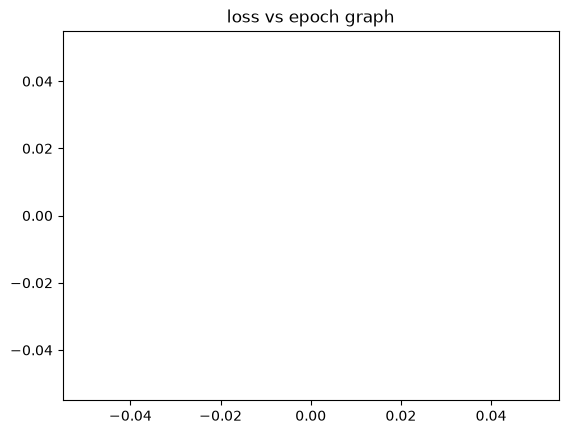

In [36]:
plt.plot(steps, losses)
plt.title("loss vs epoch graph")

In [37]:
# validation tests

with torch.no_grad():
    emb = C[Xtr] # (32, 3, 2)
    h = (emb.view(-1, 30) @ W1) # (32, 100)
    h = bngain*((h - bn_rmean)/bn_rstd) + bnbias
    h1 = torch.tanh(h)
    logits = h1 @ W2 + b2 # (32, 27)
    losstrain = F.cross_entropy(logits, Ytr)

    emb = C[Xdev] # (32, 3, 2)
    h = (emb.view(-1, 30) @ W1) # (32, 100)
    h = bngain*((h - bn_rmean)/bn_rstd) + bnbias
    h1 = torch.tanh(h)
    logits = h1 @ W2 + b2 # (32, 27)
    lossval = F.cross_entropy(logits, Ydev)

    # if nearly same, our network is underfitting. scaling up the model.
    print(f"training loss - {losstrain}\n validation loss - {lossval}")


training loss - 3.3147354125976562
 validation loss - 3.3141400814056396


#### sampling from the model
<small>

now we sample from the model as we used to before.

</small>

In [38]:
num_samples = 10
itos = {i:s for s,i in stoi.items()}

for i in range(num_samples):
    context = [0]*3
    out = []
    while True:
        emb = C[torch.tensor([context])]
        h = (emb.view(-1, 30) @ W1)
        h = bngain*((h - bn_rmean)/bn_rstd) + bnbias
        h1 = torch.tanh(h)
        logits = h1 @ W2 + b2 # (32, 27)

        probs = F.softmax(logits, dim = 1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        
        context = context[1:] + [ix]
        out.append(ix)
        if ix==0:
            break
    for i in out:
        print(itos[i], end = '')
    print()
    

otivsddfthusywofyqhtrsthlz.
oohklkalbpp.
vwmrtbptaogvjyxqgqrswfdfqqzezfauqpcamgdwjyn.
hjxcgiuxqvbkpy.
pyqktzsdepkhrwtnmikzhwfpfbkrnfmzzrgjzicoakbirdyfqnol.
rbemn.
sjbdeyftxjsoprptfiuzxlnowocbtsurtzt.
yifzvkpkadjueoglron.
zixgwttihxozyrvzsdudsyrblnoecedyotcpysvljvfeiplgynridt.
cjhjlcyuloylezbtbjsagw.


<small>

there are important things to consider when training neural nets. for example, visualizing the update:data ratio can actually signify how well we are converging in different epochs. we can log them to scale them to smaller values. it all comes down to graphing and intuition.

## picomake: loss history

### Results

| Commit | Change | Train loss | Val loss |
|---|---|---|---|
| `a764300` | Starter code, plain `randn` weights | 2.0847 | 2.1344 |
| `c9cf11c` | Tanh fix: `W1*0.1`, `W2*0.01`, zero biases | 1.9918 | 2.0943 |
| `5e45a93` | Kaiming init: `W1*(5/3)/√30` | 1.9918 (stale) | 2.0943 (stale) |
| `a2ac855` | Batch norm layer, `b1` removed | 2.0051 | 2.0813 |
| `98c4083` | Sampling only, no training change | 2.0051 | 2.0813 |

### Notes

- **Tanh fix (`c9cf11c`):** the biggest gain. Train loss dropped by about 0.093 and val by about 0.040. The step-0 loss was 3.2051, close to the ~3.3 expected from a uniform guess over 27 characters.
- **Kaiming init (`5e45a93`):** the outputs are identical to the previous commit down to the last digit, so they are stale. The init cell and the validation cell both have `execution_count: null`, meaning they were not re-run after the change. This step has no real measurement of its own; re-running the notebook would give one.
- **Batch norm (`a2ac855`):** train loss got slightly worse (1.9918 → 2.0051) but val improved (2.0943 → 2.0813). The train–val gap shrank from about 0.102 to 0.076. The step-0 loss was 3.2987.

</small>